# **Cell 1 - Mount Google Drive**

In [1]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

Mounted at /content/drive


# **Cell 2 - Path Proyek**

In [2]:
ROOT = Path("/content/drive/MyDrive/Detection Object - Yolo8")

print("Folder ada:", ROOT.exists())
print(*list(ROOT.iterdir()), sep="\n")

Folder ada: True
/content/drive/MyDrive/Detection Object - Yolo8/Tang Rivet
/content/drive/MyDrive/Detection Object - Yolo8/Penggaris Siku 25 CM
/content/drive/MyDrive/Detection Object - Yolo8/notebooks
/content/drive/MyDrive/Detection Object - Yolo8/Water Pass
/content/drive/MyDrive/Detection Object - Yolo8/app
/content/drive/MyDrive/Detection Object - Yolo8/Tekiro C Clamp
/content/drive/MyDrive/Detection Object - Yolo8/docs
/content/drive/MyDrive/Detection Object - Yolo8/Gergaji Kayu
/content/drive/MyDrive/Detection Object - Yolo8/Gergaji Besi
/content/drive/MyDrive/Detection Object - Yolo8/Meteran
/content/drive/MyDrive/Detection Object - Yolo8/Gunting
/content/drive/MyDrive/Detection Object - Yolo8/Gunting Plat
/content/drive/MyDrive/Detection Object - Yolo8/Kunci T
/content/drive/MyDrive/Detection Object - Yolo8/Tang Scun Hidrolik
/content/drive/MyDrive/Detection Object - Yolo8/runs
/content/drive/MyDrive/Detection Object - Yolo8/gallery
/content/drive/MyDrive/Detection Object - Y

# **Cell 3 - Cek dataset**

In [ ]:
for split in ["train", "valid", "test"]:
    n_img = len(list((ROOT / split / "images").glob("*.jpg")))
    n_lab = len(list((ROOT / split / "labels").glob("*.txt")))
    print(f"{split:6}  gambar={n_img:3}  label={n_lab:3}")

train   gambar=310  label=310
valid   gambar= 63  label= 63
test    gambar= 22  label= 22


# **Cell 4 - Perbaiki data.yaml**

In [ ]:
yaml_path = ROOT / "data.yaml"
yaml_path.write_text(f"""path: {ROOT}
train: train/images
val: valid/images
test: test/images
nc: 11
names: ['gergaji_besi', 'gergaji_kayu', 'gunting', 'gunting_plat', 'kunci_t', 'meteran', 'penggaris_siku', 'tang_rivet', 'tang_scun_hidrolik', 'tekiro_c_clamp', 'water_pass']
""")
print(yaml_path.read_text())

path: /content/drive/MyDrive/Detection Object - Yolo8
train: train/images
val: valid/images
test: test/images
nc: 11
names: ['gergaji_besi', 'gergaji_kayu', 'gunting', 'gunting_plat', 'kunci_t', 'meteran', 'penggaris_siku', 'tang_rivet', 'tang_scun_hidrolik', 'tekiro_c_clamp', 'water_pass']



# **Cell 5 - Install & cek GPU**

In [8]:
%pip install ultralytics -q
import torch
from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "MASIH CPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu130
GPU: Tesla T4


# **Cell 6 - Train**

In [ ]:
model = YOLO("yolov8n.pt")
model.train(
    data=str(ROOT / "data.yaml"),
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    project=str(ROOT / "runs"),
    name="colab",
)

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Detection Object - Yolo8/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=colab-3, nbs=64, nms=None, ops

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  3,  4,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bf37b24eac0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046, 

# **Cell 7- Cek hasil (setelah train selesai)**

best.pt: True


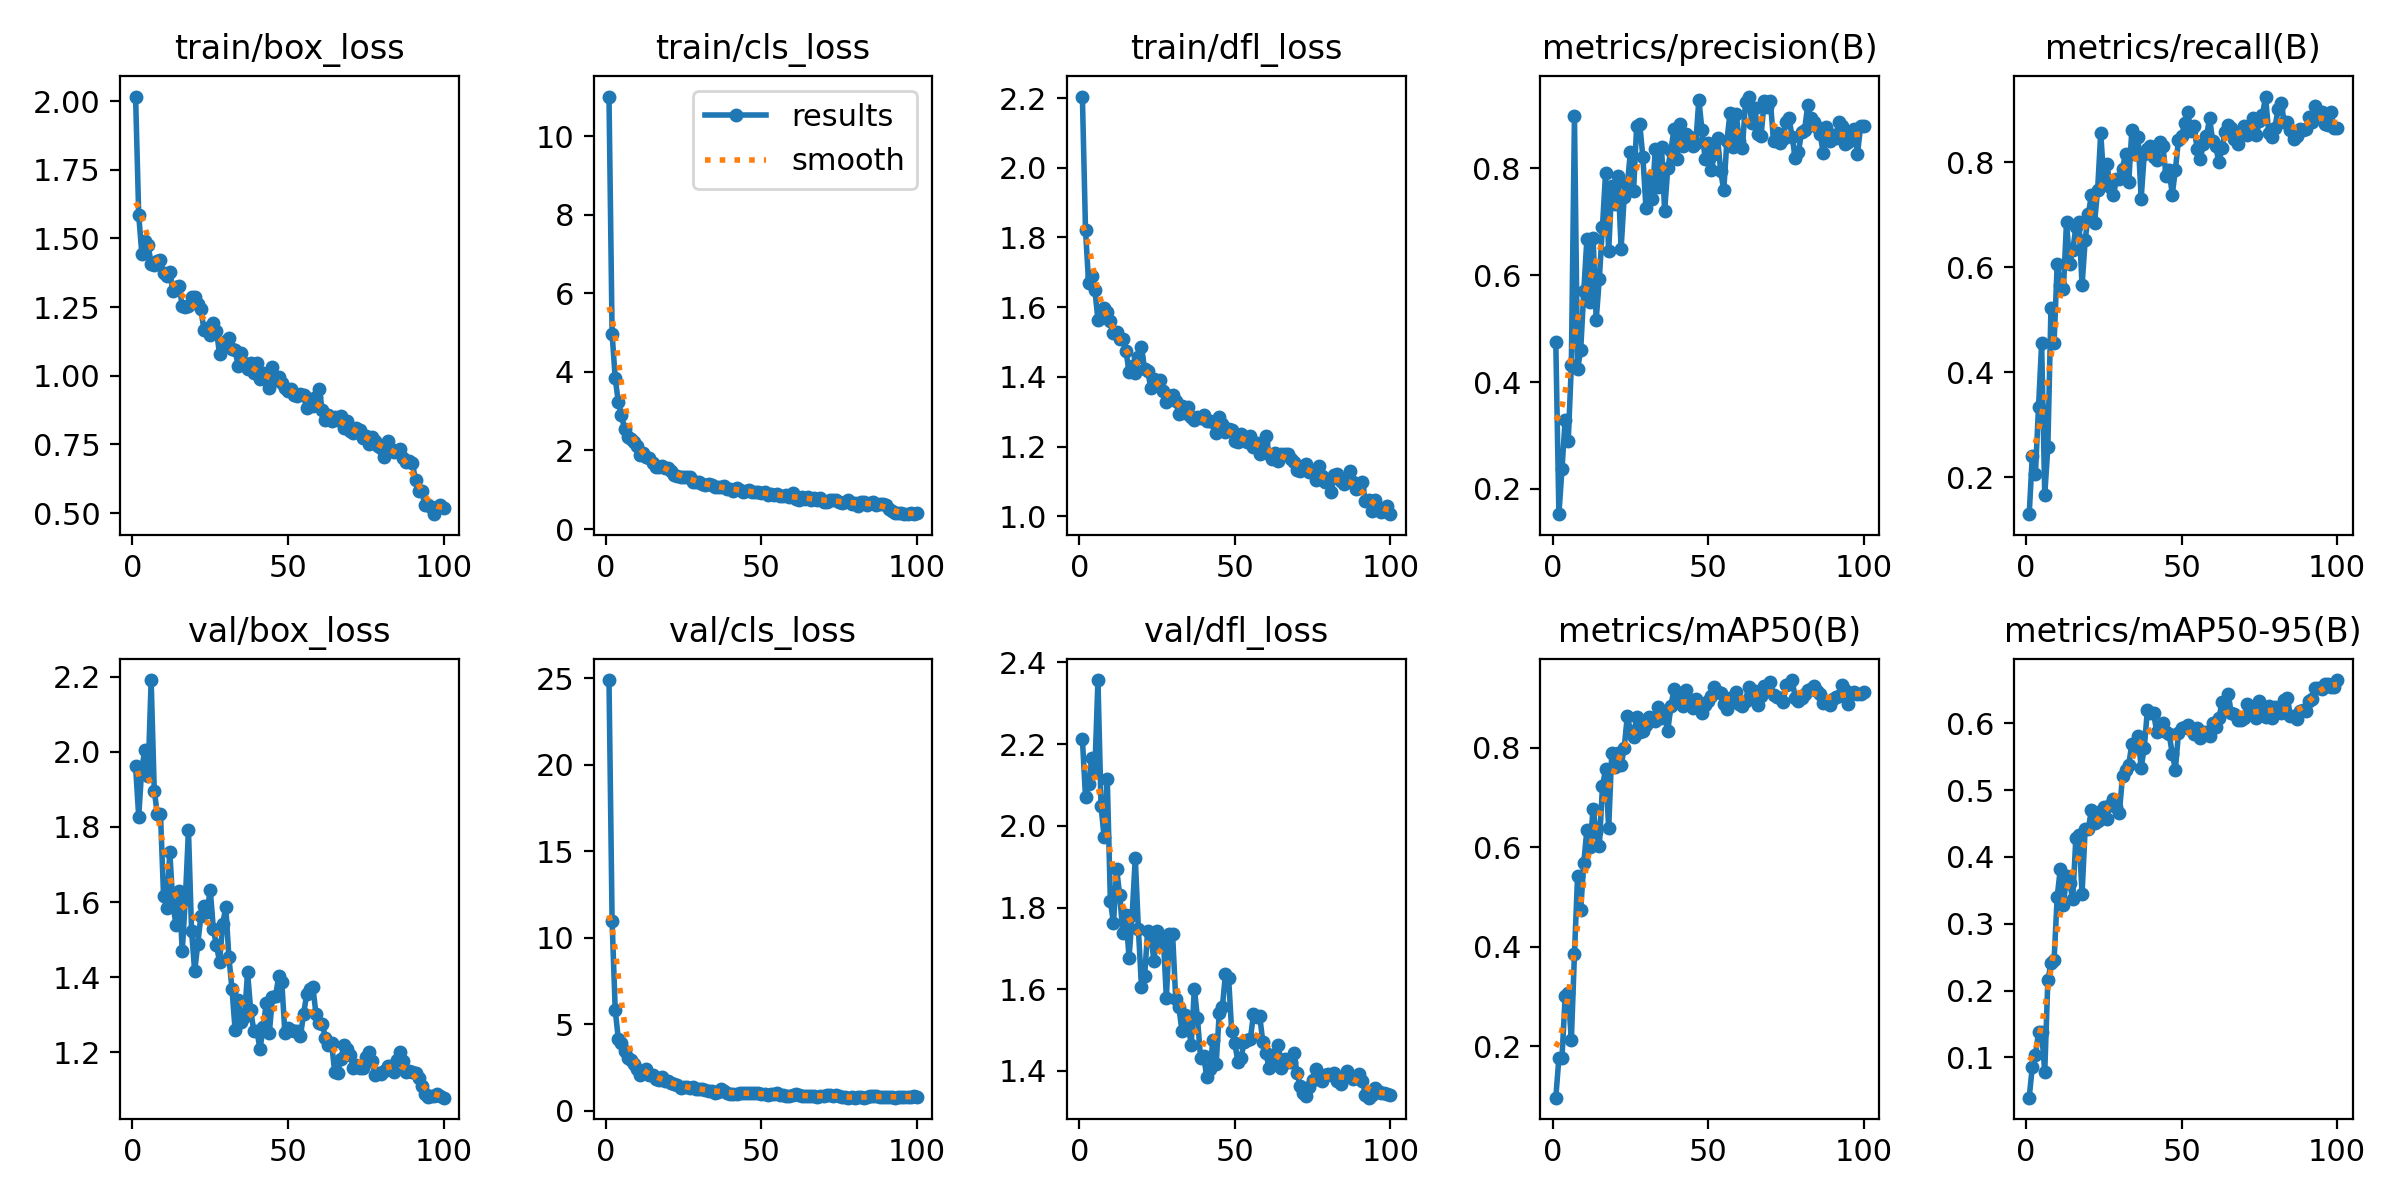

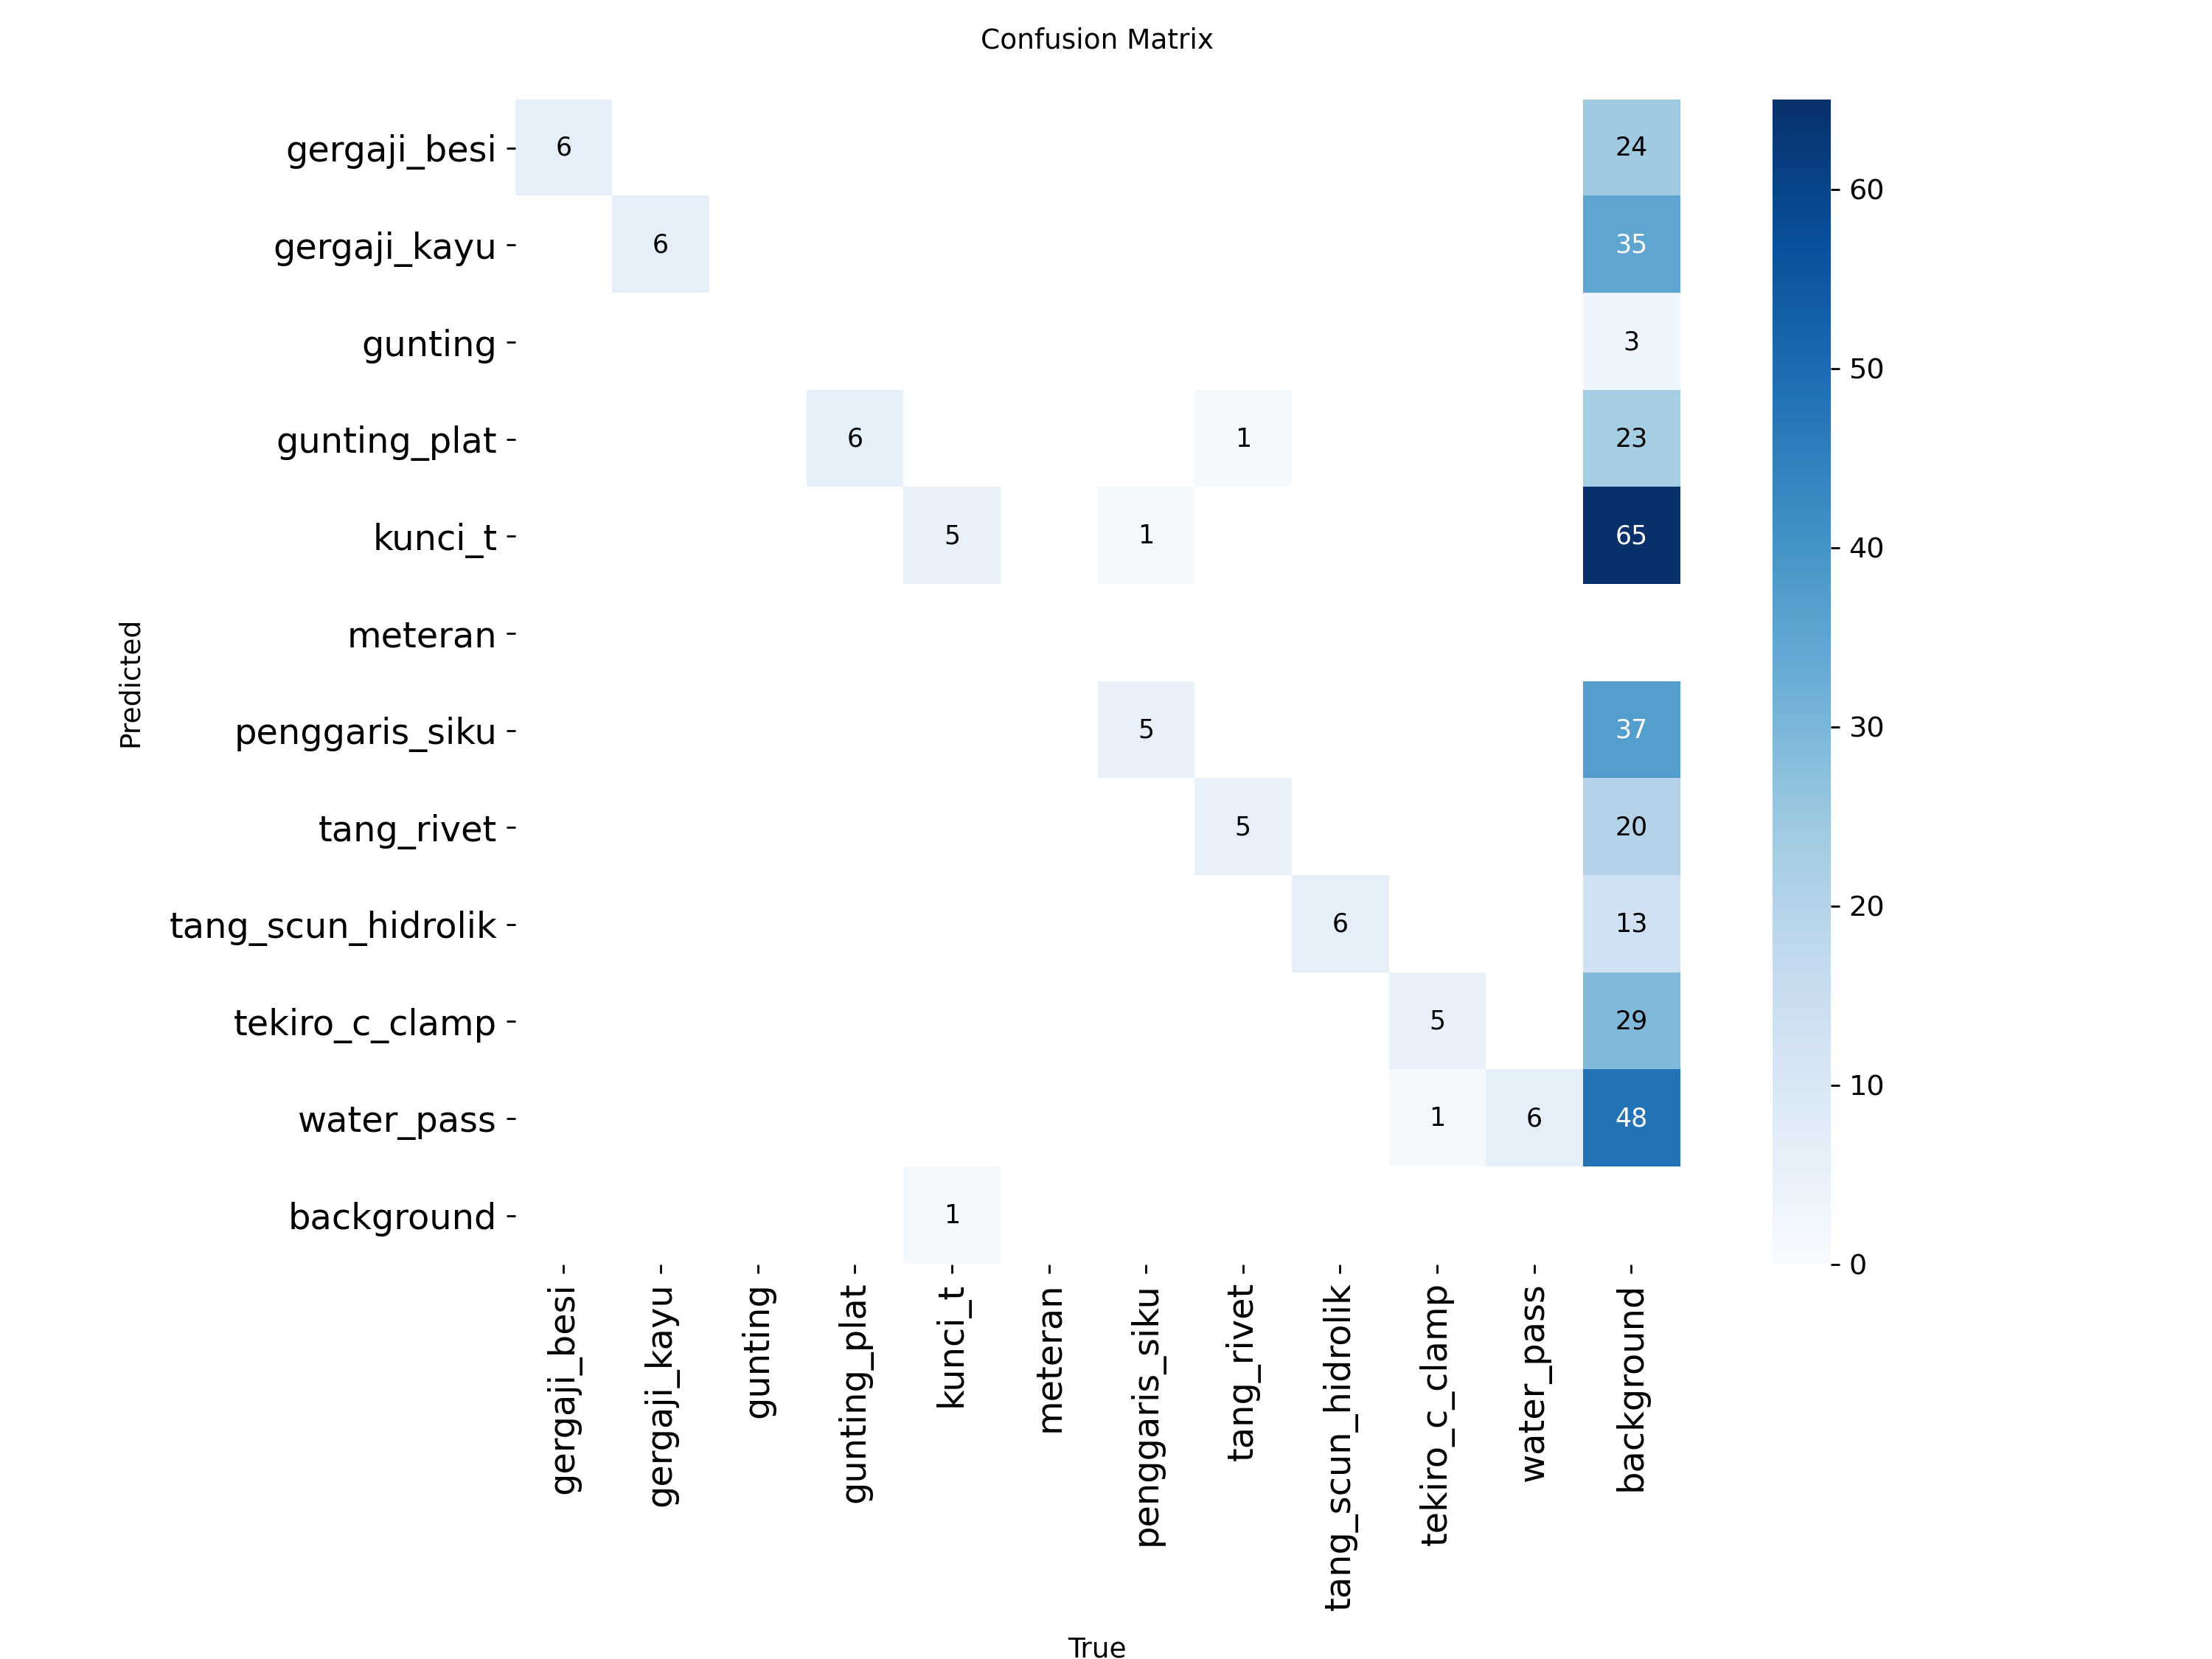

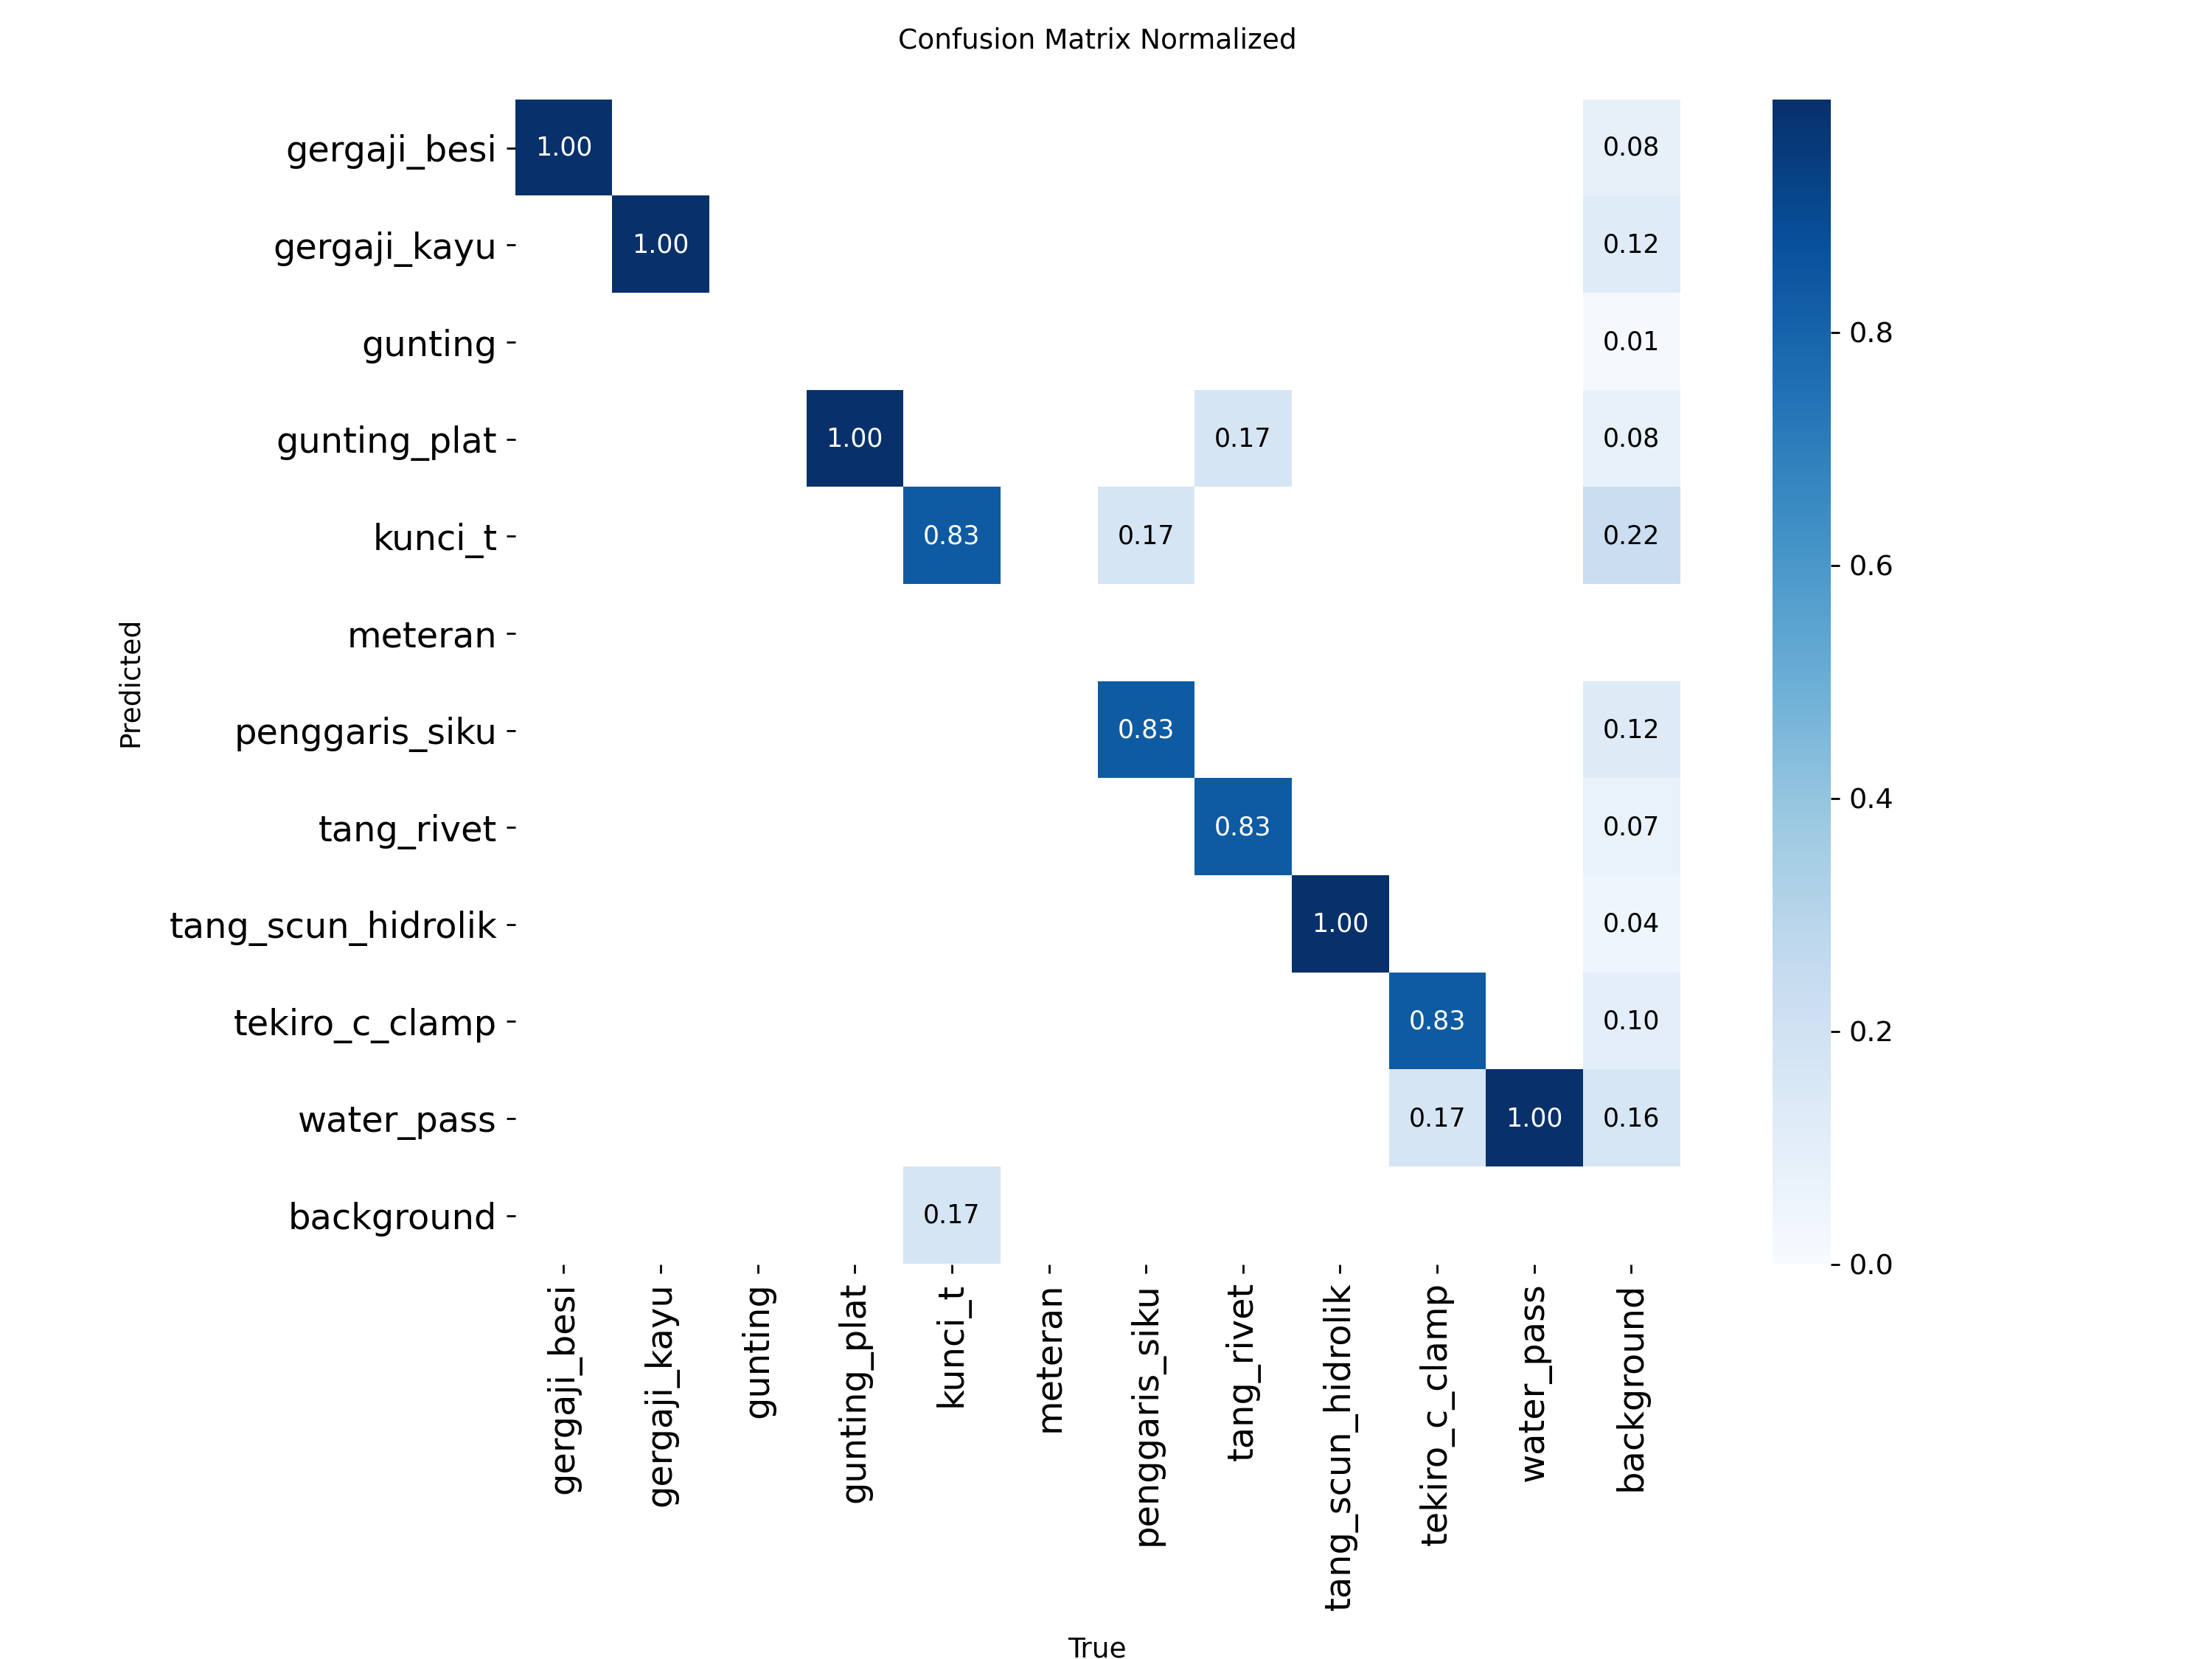

In [17]:
from IPython.display import Image, display

run = ROOT / "runs" / "colab-3"
print("best.pt:", (run / "weights" / "best.pt").exists())
for f in ["results.png", "confusion_matrix.png", "confusion_matrix_normalized.png"]:
    p = run / f
    if p.exists():
        display(Image(str(p)))

# **Cell 8 - Test 1 Folder Gambar**

In [18]:
model = YOLO(str(ROOT / "runs" / "colab-3" / "weights" / "best.pt"))

metrics = model.val(data=str(ROOT / "data.yaml"), split="test")
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

model.predict(
    source=str(ROOT / "test" / "images"),
    save=True,
    conf=0.5,
    project=str(ROOT / "runs"),
    name="predict",
)
print("Hasil:", ROOT / "runs" / "predict")

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,135,137 parameters, 0 gradients, 8.7 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.6±0.1 ms, read: 0.1±0.0 MB/s, size: 50.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Detection Object - Yolo8/test/labels... 22 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22 1.1s/it 23.2s
val: New cache created: /content/drive/MyDrive/Detection Object - Yolo8/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 6, len(boxes) = 18. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 1

# **Cell 9 - Cek gallery di Drive**

In [3]:
ROOT = Path("/content/drive/MyDrive/Detection Object - Yolo8")
GALLERY = ROOT / "gallery"
print("Gallery ada:", GALLERY.exists())
for person in sorted(GALLERY.iterdir()):
  if person.is_dir():
    gallery_drive = len(list(person.glob("*")))
    print(f"  {person.name}: {gallery_drive} foto")

Gallery ada: True
  ABDUL AZIZ FIRDAUS: 4 foto
  ALIM IKLAS MAKMURI: 4 foto
  FANDY KUSTIANTO: 4 foto
  JOKO SUPRIANTO: 4 foto
  MUHAMMAD FARHAN FAUZI: 4 foto
  RIPAL RUSANDI: 4 foto
  RYVAN HANDI BRATA: 4 foto
  SETIAJI: 4 foto
  SOFIYAN PRABOWO: 4 foto
  TEGUH WIYONO: 4 foto
  WAHYU FIRDAUS: 4 foto


# **Cell 10 - Install InsightFace**

In [4]:
%pip install insightface -q
%pip uninstall -y onnxruntime -q
%pip install onnxruntime-gpu -q
print("InsightFace siap")

InsightFace siap


# **Cell 11 - Load model wajah (bukan pakai YOLO)**

In [5]:
from insightface.app import FaceAnalysis

app = FaceAnalysis(name="buffalo_s")
app.prepare(ctx_id=0)
print("Model wajah loaded")

download_path: /root/.insightface/models/buffalo_s


100%|██████████| 124617/124617 [00:01<00:00, 76029.62KB/s]


Model wajah loaded


# **Cell 12 - Enrollment (ini "daftar nama", bukan train 100 epoch)**

In [6]:
import cv2
import numpy as np

names, vectors = [], []

for person_dir in sorted(GALLERY.iterdir()):
  if not person_dir.is_dir():
    continue
  embs = []
  for img_path in person_dir.glob("*"):
    img = cv2.imread(str(img_path))
    if img is None:
      continue
    faces = app.get(img)
    if not faces:
      print("Tidak ada wajah:", img_path)
      continue
    face = max(faces, key=lambda f: (f.bbox[2] - f.bbox[0]) * (f.bbox[3] - f.bbox[1]))
    embs.append(face.normed_embedding)
  if embs:
    names.append(person_dir.name)
    vectors.append(np.mean(embs, axis=0))
    print(person_dir.name, "ok,", len(embs), "foto")

vectors = np.stack(vectors)
vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)
out = str(ROOT / "gallery_embeddings.npz")
np.savez(out, names=np.array(names), embeddings=np.array(vectors))
print("Tersimpan:", out)
print("Orang:", names)

ABDUL AZIZ FIRDAUS ok, 4 foto
ALIM IKLAS MAKMURI ok, 4 foto
FANDY KUSTIANTO ok, 4 foto
JOKO SUPRIANTO ok, 4 foto
MUHAMMAD FARHAN FAUZI ok, 4 foto
RIPAL RUSANDI ok, 4 foto
RYVAN HANDI BRATA ok, 4 foto
SETIAJI ok, 4 foto
SOFIYAN PRABOWO ok, 4 foto
TEGUH WIYONO ok, 4 foto
WAHYU FIRDAUS ok, 4 foto
Tersimpan: /content/drive/MyDrive/Detection Object - Yolo8/gallery_embeddings.npz
Orang: ['ABDUL AZIZ FIRDAUS', 'ALIM IKLAS MAKMURI', 'FANDY KUSTIANTO', 'JOKO SUPRIANTO', 'MUHAMMAD FARHAN FAUZI', 'RIPAL RUSANDI', 'RYVAN HANDI BRATA', 'SETIAJI', 'SOFIYAN PRABOWO', 'TEGUH WIYONO', 'WAHYU FIRDAUS']


# **Cell 13 - Fungsi kenali nama**

In [10]:
data = np.load(ROOT / "gallery_embeddings.npz", allow_pickle=True)
GALLERY_NAMES = data["names"]
GALLERY_EMB = data["embeddings"]
THRESH = 0.40

def identify(face):
  sim = GALLERY_EMB @ face.normed_embedding
  i = int(np.argmax(sim))
  score = float(sim[i])
  if score < THRESH:
    return "unknown", score
  return str(GALLERY_NAMES[i]), score

# **Cell 14 - Test 1 foto (alat + nama)**

==== test_Setiaji.jpeg ok
==== test_Ryvan.jpg ok
==== test_Ripal.jpeg ok
==== test_Aziz.jpeg ok
==== test_Bowo.jpg ok
==== test_Farhan.jpg ok
==== test_Teguh.jpg ok
==== test_Joko.jpg ok
==== test_Fandy.jpg ok
==== test_Wahyu.jpg ok
==== test_Alim.jpg ok


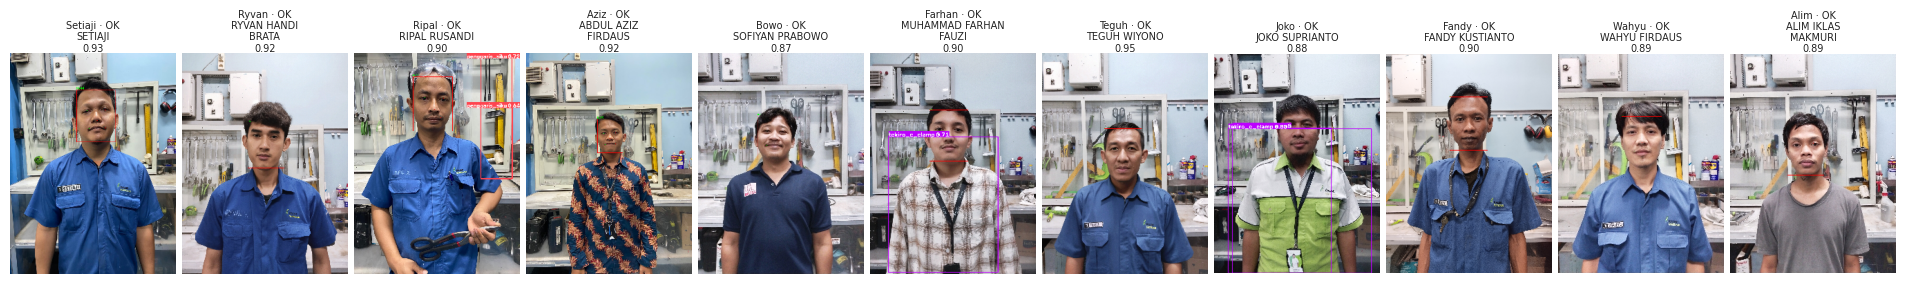

Akurasi wajah: 11/11 = 100%


In [13]:
from matplotlib import pyplot as plt
import cv2

yolo = YOLO(str(ROOT / "runs" / "colab-3" / "weights" / "best.pt"))

nama_file = [
    "test_Setiaji.jpeg", "test_Ryvan.jpg", "test_Ripal.jpeg", "test_Aziz.jpeg",
    "test_Bowo.jpg", "test_Farhan.jpg", "test_Teguh.jpg", "test_Joko.jpg", "test_Fandy.jpg", "test_Wahyu.jpg", "test_Alim.jpg"
]

hasil = []
benar_wajah = 0
total = 0

for nama in nama_file:
    path = ROOT / "teknisi" / nama
    img = cv2.imread(str(path))
    print("====", path.name, "ok" if img is not None else "GAGAL")
    if img is None:
        continue

    tools = yolo.predict(img, conf=0.5, verbose=False)[0]
    if tools.boxes and len(tools.boxes):
        alat = [
            f"{tools.names[int(c)]} {float(p):.2f}"
            for c, p in zip(tools.boxes.cls, tools.boxes.conf)
        ]
    else:
        alat = []

    faces = app.get(img)
    people = [identify(f) for f in faces]
    drawn = app.draw_on(tools.plot(), faces)

    kunci = path.stem.replace("test_", "").lower()
    nama_ok, skor_ok = "-", 0.0
    cocok = False
    if people:
        nama_ok, skor_ok = people[0]
        cocok = kunci in nama_ok.lower()

    total += 1
    benar_wajah += int(cocok)

    h, w = drawn.shape[:2]
    drawn = cv2.resize(drawn, (240, int(h * 240 / w)))
    hasil.append({
        "judul": path.stem.replace("test_", ""),
        "nama": nama_ok,
        "skor": skor_ok,
        "alat": ", ".join(alat) or "-",
        "cocok": cocok,
        "img": drawn,
    })

n = len(hasil)
h0, w0 = hasil[0]["img"].shape[:2]
fig, axes = plt.subplots(1, n, figsize=(n * w0 / 140, h0 / 140 + 0.55))
axes = [axes] if n == 1 else list(axes)

for ax, item in zip(axes, hasil):
    ax.imshow(cv2.cvtColor(item["img"], cv2.COLOR_BGR2RGB))
    status = "OK" if item["cocok"] else "salah"
    nama = item["nama"]
    potong = nama.split()
    if len(potong) >= 3:
        nama = " ".join(potong[:2]) + "\n" + " ".join(potong[2:])
    ax.set_title(
        f"{item['judul']} · {status}\n{nama}\n{item['skor']:.2f}",
        fontsize=7,
        pad=2,
        color="#222222",
        fontweight="normal",
        linespacing=1.15,
    )
    ax.axis("off")
    ax.set_aspect("equal")

fig.subplots_adjust(left=0, right=1, top=0.78, bottom=0, wspace=0.04)
plt.show()
print(f"Akurasi wajah: {benar_wajah}/{total} = {100 * benar_wajah / total:.0f}%" if total else "Tidak ada foto")